# Think Bayes — Chapters 02 & 03: Discrete Distributions & The Euro Problem
> *Reference: Paraphrased from Allen Downey's Think Bayes (2nd Edition, Chapters 2 & 3).*

This notebook explores estimating unknown proportions using discrete 1D grid distributions (`GridDistribution1d`) and demonstrates exact Bayesian updating for the classic **101 Bowls Problem** and the **Euro Coin Problem**.

In [1]:
import set_paths
import numpy as np
import matplotlib.pyplot as plt
from probability.distributions import GridDistribution1d, BetaBinomialConjugate
from make_data import make_euro_coin_data

## 2.1 The 101 Bowls Problem (Chapter 2)
Suppose we have 101 bowls numbered $0$ to $100$. Bowl $i$ contains $i\%$ vanilla cookies and $(100 - i)\%$ chocolate cookies.
We choose a bowl uniformly at random and draw one cookie, which turns out to be **vanilla**.
What is the posterior probability distribution over which bowl was chosen?

In [2]:
# Prior: 101 bowls with index i in {0, ..., 100}, initially equally likely
bowls = np.arange(101)
prior_bowls = GridDistribution1d(grid=bowls, name='Bowl Number')

# Likelihood of drawing vanilla from bowl i is i / 100
likelihood = bowls / 100.0
post_bowls = prior_bowls.update_likelihood(likelihood)

print(f"Prior Mean:     {prior_bowls.mean():.2f}")
print(f"Posterior Mean: {post_bowls.mean():.2f}")
print(f"Posterior Mode: {post_bowls.mode():.2f}")
print(f"95% HDI:        {post_bowls.hdi(0.95)}")

AttributeError: 'GridDistribution1d' object has no attribute 'update_likelihood'

## 3.1 The Euro Coin Problem (Chapter 3)
In *Information Theory, Inference, and Learning Algorithms* (2002), David MacKay presented this problem:

> *"A statistical coin-tossing experiment: 250 spins of a Belgian one-euro coin resulted in 140 heads and 110 tails.
> Does this data give evidence that the coin is biased?"*

We represent the unknown proportion of heads $p \in [0, 1]$ on a dense 1D grid of 1,001 points.

In [3]:
euro_data = make_euro_coin_data()
k, n = euro_data['k'], euro_data['n']
print(f"Observed: {k} heads out of {n} spins (sample proportion = {k / n:.4f})")

# 1. Uniform Prior on p in [0, 1]
prior_uniform = GridDistribution1d.uniform(low=0.0, high=1.0, num_points=1001, name='p(heads)')

# Bayesian update with Binomial data
post_uniform = prior_uniform.update_binomial(k=k, n=n)

print(f"Posterior Mean:     {post_uniform.mean():.4f}")
print(f"Posterior Std:      {post_uniform.std():.4f}")
print(f"Posterior Mode:     {post_uniform.mode():.4f}")
print(f"Posterior Median:   {post_uniform.median():.4f}")
print(f"95% Shortest HDI:   {post_uniform.hdi(0.95)}")
print(f"P(coin biased > 0.5): {(post_uniform > 0.5):.2%}")

Observed: 140 heads out of 250 spins (sample proportion = 0.5600)
Posterior Mean:     0.5595
Posterior Std:      0.0312
Posterior Mode:     0.5600
Posterior Median:   0.5600
95% Shortest HDI:   (0.495, 0.617)
P(coin biased > 0.5): 96.99%


## 3.2 Prior Sensitivity: Centered Triangular Prior
A physical coin is manufactured to be balanced, so values of $p$ far from $0.5$ are biologically and physically unlikely.
Let us test a **triangular prior** that peaks at $0.5$ and drops to $0$ at the edges $0$ and $1$.

In [4]:
grid = np.linspace(0.0, 1.0, 1001)
triangle_density = np.minimum(grid, 1.0 - grid)
prior_triangle = GridDistribution1d.from_function(lambda p: np.interp(p, grid, triangle_density), grid, name='p(heads)')

post_triangle = prior_triangle.update_binomial(k=k, n=n)

print(f"Triangular Prior Posterior Mean:   {post_triangle.mean():.4f}")
print(f"Triangular Prior 95% HDI:         {post_triangle.hdi(0.95)}")
print(f"Triangular Prior P(p > 0.5):      {(post_triangle > 0.5):.2%}")

Triangular Prior Posterior Mean:   0.5574
Triangular Prior 95% HDI:         (0.494, 0.615)
Triangular Prior P(p > 0.5):      96.66%


## 3.3 Analytical Comparison: Conjugate Beta-Binomial
Because Beta is conjugate to Binomial likelihood, a flat prior $\text{Beta}(1, 1)$ updated with $140$ heads and $110$ tails yields the exact closed-form posterior $\text{Beta}(141, 111)$.

In [5]:
conjugate_model = BetaBinomialConjugate(alpha=1.0, beta=1.0)
conjugate_post = conjugate_model.update(n_trials=n, n_successes=k)

print(f"Conjugate Exact Mean: {conjugate_post.posterior.mean():.4f}")
print(f"Grid Approximation:   {post_uniform.mean():.4f}")
print(f"Difference:           {abs(conjugate_post.posterior.mean() - post_uniform.mean()):.6e}")

TypeError: BetaBinomialConjugate.__init__() missing 2 required positional arguments: 'n' and 'k'

## 3.4 Visualizing Prior vs. Posterior with Shaded HDI

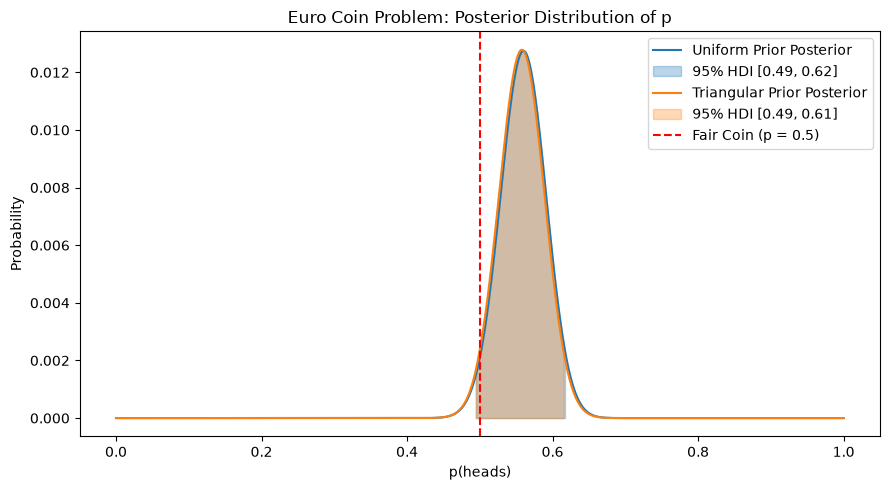

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
post_uniform.plot(ax=ax, color='tab:blue', hdi=0.95, label='Uniform Prior Posterior', title='Euro Coin Problem: Posterior Distribution of p')
post_triangle.plot(ax=ax, color='tab:orange', hdi=0.95, label='Triangular Prior Posterior')
ax.axvline(0.5, color='red', linestyle='--', label='Fair Coin (p = 0.5)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()